# Gaussian Mixture Models: OOD Detection and Image Segmentation

**Introduction to Machine Learning · Phase 1**  
Sharif University of Technology · Department of Electrical Engineering  
**Farzan Aghaei · Mohammadkazem Shahrabi**

This notebook implements Gaussian mixture models (GMMs) and expectation–maximization (EM) from scratch. Experiments include likelihood-based OOD detection on synthetic 2D data and RGB pixel clustering for image segmentation.

## 1. Multivariate Gaussian density

Compute the density using the covariance determinant and quadratic form.

In [1]:
import numpy as np

def gaussian_pdf(x, mean, cov):
    x = np.atleast_2d(x)
    mean = np.asarray(mean).reshape(1, -1)
    cov = np.asarray(cov)

    d = x.shape[1]
    diff = x - mean

    inv_cov = np.linalg.inv(cov)
    det_cov = np.linalg.det(cov)
    det_cov = max(det_cov, 1e-12)

    norm_const = 1.0 / np.sqrt(((2 * np.pi) ** d) * det_cov)
    quad = np.einsum("ni,ij,nj->n", diff, inv_cov, diff)
    exp_term = np.exp(-0.5 * quad)

    return norm_const * exp_term


## 2. Gaussian mixture model and EM

Fit mixture weights, means and covariance matrices by iterating E- and M-steps.

In [2]:
class GMM:
    def __init__(self, n_components, max_iters=100, tol=1e-3):
        self.K = n_components
        self.max_iters = max_iters
        self.tol = tol

    def initialize(self, X):
        n, d = X.shape
        rng = np.random.default_rng()

        idx = rng.choice(n, size=self.K, replace=False)
        self.means = X[idx].copy()

        base_cov = np.cov(X.T) + 1e-6 * np.eye(d)
        self.covs = np.stack([base_cov.copy() for _ in range(self.K)], axis=0)

        self.weights = np.ones(self.K) / self.K

    def e_step(self, X):
        n = X.shape[0]
        gamma = np.zeros((n, self.K))

        for k in range(self.K):
            gamma[:, k] = self.weights[k] * gaussian_pdf(X, self.means[k], self.covs[k])

        denom = gamma.sum(axis=1, keepdims=True)
        denom = np.maximum(denom, 1e-300)
        gamma = gamma / denom
        return gamma

    def m_step(self, X, gamma):
        n, d = X.shape
        Nk = gamma.sum(axis=0)
        Nk = np.maximum(Nk, 1e-12)

        self.weights = Nk / n
        self.means = (gamma.T @ X) / Nk[:, None]

        covs = np.zeros((self.K, d, d))
        for k in range(self.K):
            diff = X - self.means[k]
            covs[k] = (gamma[:, k][:, None] * diff).T @ diff / Nk[k]
            covs[k] += 1e-6 * np.eye(d)
        self.covs = covs

    def log_likelihood(self, X):
        X = np.atleast_2d(X)
        n = X.shape[0]
        comp = np.zeros((n, self.K))
        for k in range(self.K):
            comp[:, k] = self.weights[k] * gaussian_pdf(X, self.means[k], self.covs[k])
        total = comp.sum(axis=1)
        total = np.maximum(total, 1e-300)
        ll = np.log(total)
        return ll

    def fit(self, X):
        self.initialize(X)
        prev_ll = None

        for i in range(self.max_iters):
            gamma = self.e_step(X)
            self.m_step(X, gamma)
            ll = self.log_likelihood(X).mean()

            if prev_ll is not None and abs(ll - prev_ll) < self.tol:
                break
            prev_ll = ll

        print(f"EM converged in {i+1} iterations")


## 3. Synthetic 2D dataset

Generate two Gaussian clusters as in-distribution data and uniformly distributed outliers.

In [3]:
np.random.seed(0)

# ID data (mixture of Gaussians)
N = 600
X1 = np.random.multivariate_normal([0, 0], [[0.8, 0.2], [0.2, 0.6]], N // 2)
X2 = np.random.multivariate_normal([3, 3], [[0.6, -0.1], [-0.1, 0.6]], N // 2)
X_id = np.vstack([X1, X2])

# OOD data (far away)
X_ood = np.random.uniform(low=-6, high=6, size=(200, 2))


## 4. Fit the two-component GMM

In [4]:
gmm = GMM(n_components=2, max_iters=200, tol=1e-4)

gmm.fit(X_id)


EM converged in 48 iterations


## 5. Likelihood-based OOD detection

Select the detection threshold as the 5th percentile of the *training* ID log-likelihoods and visualize the predictions.

In [5]:
ll_id = gmm.log_likelihood(X_id)
ll_ood = gmm.log_likelihood(X_ood)

threshold = np.percentile(ll_id, 5)

pred_id = (ll_id < threshold).astype(int)
pred_ood = (ll_ood < threshold).astype(int)


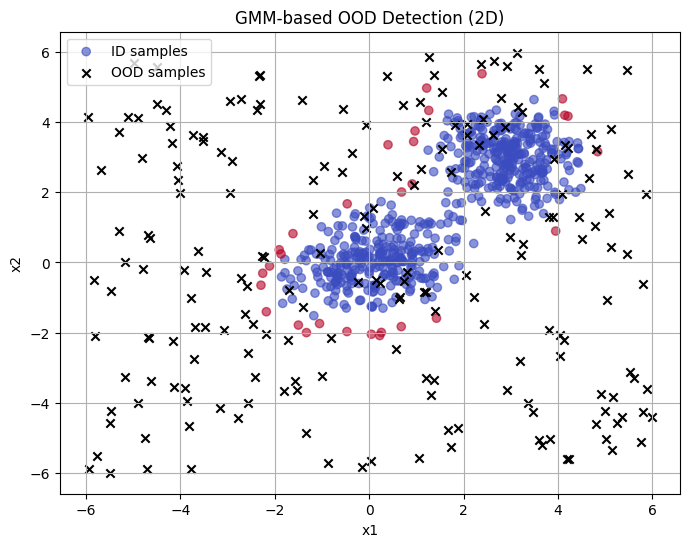

In [6]:
import matplotlib.pyplot as plt
# =========================
# Visualization
# =========================
plt.figure(figsize=(8, 6))
plt.scatter(X_id[:, 0], X_id[:, 1],
            c=pred_id, cmap="coolwarm", alpha=0.6, label="ID samples")
plt.scatter(X_ood[:, 0], X_ood[:, 1],
            c="black", marker="x", label="OOD samples")
plt.legend()
plt.title("GMM-based OOD Detection (2D)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True)
plt.show()

**Interpretation.** The fitted GMM assigns each sample a log-density $\log p(x)=\log\sum_k\pi_k\mathcal{N}(x\mid\mu_k,\Sigma_k)$. The 5th-percentile threshold is calibrated on the *same ID observations used for fitting*; it yields approximately 5% flagged training ID samples by construction, **not** an independent test-set false-positive-rate estimate. OOD performance depends on the chosen outlier distribution and model fit.

# GMM-Based Image Segmentation

Each image pixel is represented by its RGB intensity vector and assigned to the mixture component with the highest posterior responsibility. This section defines its own GMM implementation so it can be studied independently.

## 6. Multivariate Gaussian density for image features

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from skimage import data, transform, img_as_float

def gaussian_pdf(x, mean, cov):
    x = np.atleast_2d(x)
    mean = np.asarray(mean).reshape(1, -1)
    cov = np.asarray(cov)

    d = x.shape[1]
    diff = x - mean

    inv_cov = np.linalg.inv(cov)
    det_cov = np.linalg.det(cov)
    det_cov = max(det_cov, 1e-12)

    norm_const = 1.0 / np.sqrt(((2 * np.pi) ** d) * det_cov)
    quad = np.einsum("ni,ij,nj->n", diff, inv_cov, diff)
    exp_term = np.exp(-0.5 * quad)

    return norm_const * exp_term


## 7. GMM clustering for RGB pixels

In [8]:
class GMM:
    def __init__(self, n_components, max_iters=40, tol=1e-3):
        self.K = n_components
        self.max_iters = max_iters
        self.tol = tol

    def initialize(self, X):
        n, d = X.shape
        rng = np.random.default_rng()

        idx = rng.choice(n, size=self.K, replace=False)
        self.means = X[idx].copy()

        base_cov = np.cov(X.T) + 1e-6 * np.eye(d)
        self.covs = np.stack([base_cov.copy() for _ in range(self.K)], axis=0)

        self.weights = np.ones(self.K) / self.K

    def e_step(self, X):
        n = X.shape[0]
        gamma = np.zeros((n, self.K))

        for k in range(self.K):
            gamma[:, k] = self.weights[k] * gaussian_pdf(X, self.means[k], self.covs[k])

        denom = gamma.sum(axis=1, keepdims=True)
        denom = np.maximum(denom, 1e-300)
        gamma = gamma / denom
        return gamma

    def m_step(self, X, gamma):
        n, d = X.shape
        Nk = gamma.sum(axis=0)
        Nk = np.maximum(Nk, 1e-12)

        self.weights = Nk / n
        self.means = (gamma.T @ X) / Nk[:, None]

        covs = np.zeros((self.K, d, d))
        for k in range(self.K):
            diff = X - self.means[k]
            covs[k] = (gamma[:, k][:, None] * diff).T @ diff / Nk[k]
            covs[k] += 1e-6 * np.eye(d)
        self.covs = covs

    def fit(self, X):
        self.initialize(X)
        prev_ll = None

        for _ in range(self.max_iters):
            gamma = self.e_step(X)
            self.m_step(X, gamma)

            comp = np.zeros((X.shape[0], self.K))
            for k in range(self.K):
                comp[:, k] = self.weights[k] * gaussian_pdf(X, self.means[k], self.covs[k])
            total = np.maximum(comp.sum(axis=1), 1e-300)
            ll = np.log(total).mean()

            if prev_ll is not None and abs(ll - prev_ll) < self.tol:
                break
            prev_ll = ll

    def predict(self, X):
        gamma = self.e_step(X)
        return np.argmax(gamma, axis=1)


## 8. Visualizing image segmentation

In [9]:
def segment_image(image, K, title):
      """
      Segment a color image using GMM clustering.

      image : ndarray
          Input image (H x W x 3 or grayscale)
      K : int
          Number of clusters
      title : str
          Title for the original image

      """

      image = img_as_float(image)
      image = transform.resize(image, (256, 256), anti_aliasing=True)

      if image.ndim == 2:
          image = np.stack([image, image, image], axis=-1)

      H, W, _ = image.shape

      X = image.reshape(-1, 3)

      gmm = GMM(n_components=K, max_iters=40, tol=1e-3)
      gmm.fit(X)

      labels = gmm.predict(X)
      label_map = labels.reshape(H, W)

      cmap = plt.get_cmap("tab10", K)

      legend_elements = [mpatches.Patch(color=cmap(i), label=f"Cluster {i}") for i in range(K)]

      plt.figure(figsize=(10, 4))

      plt.subplot(1, 2, 1)
      plt.imshow(image)
      plt.title(f"Original – {title}")
      plt.axis("off")

      plt.subplot(1, 2, 2)
      plt.imshow(label_map, cmap=cmap, vmin=0, vmax=K-1)
      plt.title("GMM Segmentation (Labels)")
      plt.axis("off")
      plt.legend(handles=legend_elements,
                bbox_to_anchor=(1.05, 1),
                loc="upper left",
                borderaxespad=0.)

      plt.tight_layout()
      plt.show()


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


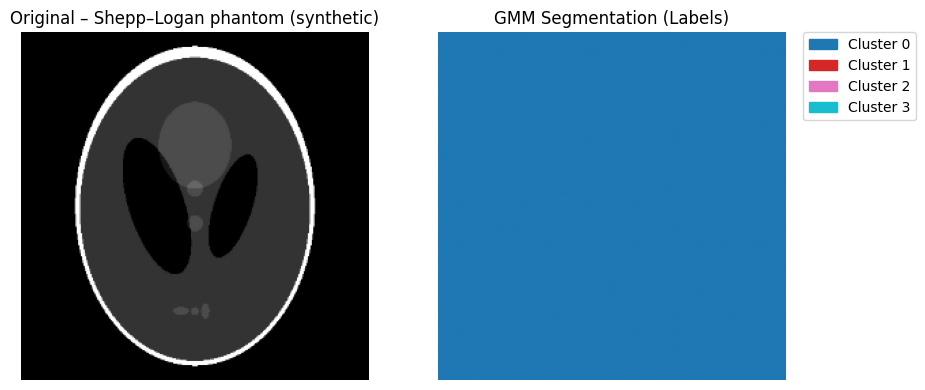

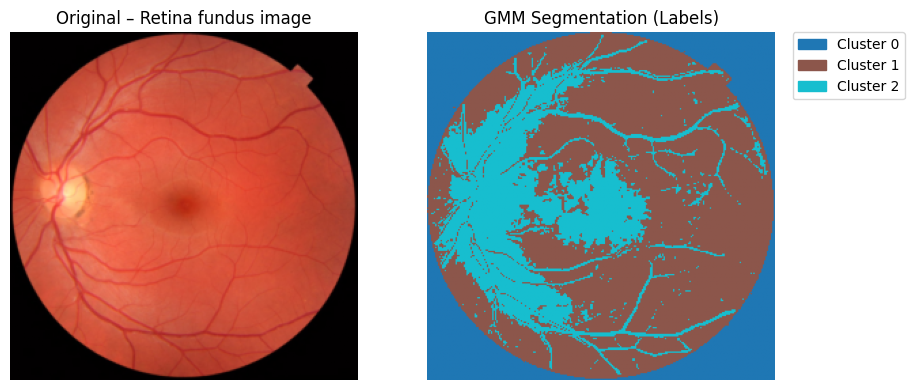

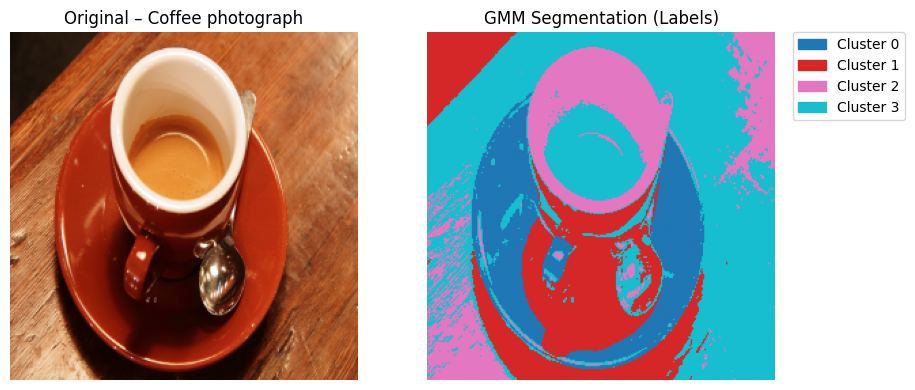

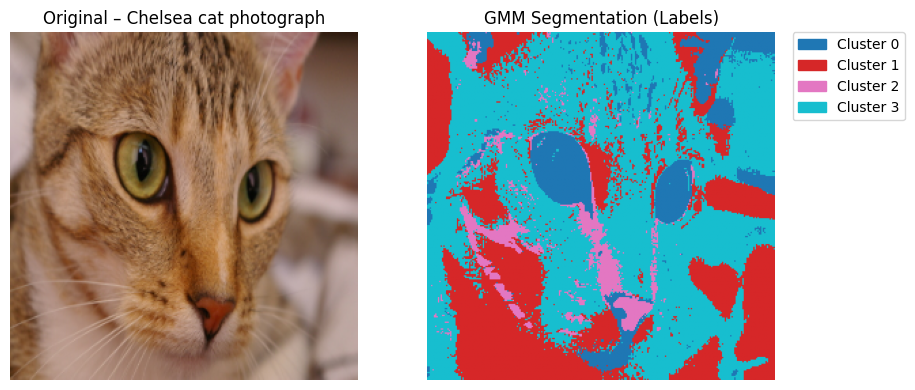

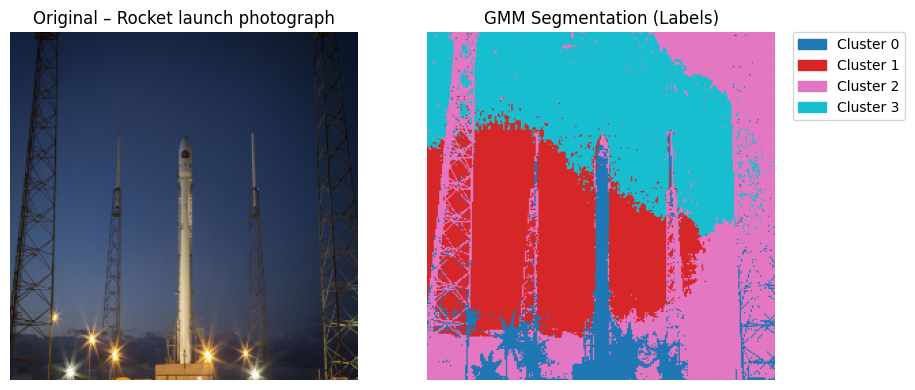

In [10]:
# =========================
# Run experiments
# =========================

segment_image(data.shepp_logan_phantom(), 4,
              "Shepp–Logan phantom (synthetic)")

segment_image(data.retina(),  K=3, title="Retina fundus image")

segment_image(data.coffee(), 4,
              "Coffee photograph")

segment_image(data.chelsea(), 4,
              "Chelsea cat photograph")

segment_image(data.rocket(), 4,
              "Rocket launch photograph")


> **Discussion**  
> For image segmentation, each pixel is treated as a 3D sample $x\in\mathbb{R}^3$ in RGB space. A $K$-component GMM clusters these pixels by fitting  
> $p(x)=\sum_{k=1}^{K} \pi_k\,\mathcal{N}(x\mid\mu_k,\Sigma_k)$.  
>  
> After EM fitting, each pixel is assigned to the component with the highest responsibility $\arg\max_k\,\gamma_{k}(x)$. The resulting label map is a clustering-based segmentation: regions with similar color statistics are grouped together.  
>  
> Since this method uses only color information (no spatial smoothness), boundaries may be noisy in textured areas; increasing $K$ can capture more color modes but may also over-segment the image.